<a href="https://colab.research.google.com/github/camilevs/Amigo_Das_Ruas/blob/main/Amigo_das_Ruas_Dynamic_Programming.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Ficha da CitizenTech

| Campo | Definição |
| --- | --- |
| **Nome da CitizenTech** | Amigo das Ruas |
| **Cidade e bairro** | São Paulo — região da Avenida Paulista (entorno do campus da FIAP) |
| **Cidadão beneficiado** | Pessoas com deficiência (cadeirantes e deficiência visual), idosos e pessoas com mobilidade reduzida |
| **Problema, em uma frase** | Falta informação confiável e filtrável sobre a acessibilidade real das calçadas e dos estabelecimentos da Paulista antes do deslocamento |
| **Papel desta disciplina** | Motor de rotas acessíveis por programação dinâmica, integrado ao ranking de reputação dos estabelecimentos |
| **Indicador de impacto** | Trechos e estabelecimentos avaliados, taxa de relatos respondidos/resolvidos e reputação média de acessibilidade |
| **ODS conectados** | ODS 10 (Redução das desigualdades) e ODS 11 (Cidades e comunidades sustentáveis) |
| **Turma** | 2ESPS |
| **Integrantes e RMs** | Camile Vitória Silva — RM 566649; Gustavo Almeida Ferreira — RM 566980; Lucas de Oliveira Miranda Caetano — RM 568036; Marco Túlio Longo Conte — RM 568373; Sofia Souza Rodrigues — RM 566708 |
| **Link do repositório** | https://github.com/JustGuslav0/Amigo_das_Ruas-2ESPS_GS-2026.git |


# **Amigo das Ruas | Dynamic Programming**

**Global Solution 2026.2 — CitizenTech (Recorte MVP: Região da Avenida Paulista)**

Este notebook implementa, em Python, o motor de roteirização acessível e ranqueamento de estabelecimentos da plataforma **Amigo das Ruas** em um mapa urbano **inteiramente simulado** da região da Avenida Paulista.

Alinhado ao escopo consolidado do projeto, o sistema foca exclusivamente em **Acessibilidade**, atendendo a três perfis de mobilidade:
1. **Cadeirante (`cadeirante`)**
2. **Pessoa com Deficiência Visual (`deficiencia_visual`)**
3. **Idoso / Mobilidade Reduzida (`mobilidade_reduzida`)**

A solução utiliza uma matriz 2D e **Programação Dinâmica (tabulação)** para calcular a rota de menor custo evitando barreiras físicas incompatíveis com cada perfil, integrando-se à aba de **Reputação e Transparência (estilo Reclame Aqui)** para filtrar e ranquear estabelecimentos próximos conforme a nota de acessibilidade específica do usuário.

> **Nota Metodológica e Ética:** Os deslocamentos são restritos **para a direita e para baixo** (simplificação acadêmica em grade, não um motor de GPS real). Todos os obstáculos, notas e nomes de estabelecimentos são **inteiramente simulados**, sem exposição de dados pessoais ou atribuição de reclamações fictícias a empresas reais.

**Fonte dos dados:** geração manual e determinística neste notebook. Nenhum dataset ou API externo foi utilizado.

**Como usar:** execute as células em ordem (ou *Ambiente de execução → Executar tudo*). Os mapas gerados em PNG são salvos na pasta `resultados/`.

## 1. Dados simulados e definição do cenário (Avenida Paulista)

In [1]:
"""Amigo das Ruas — Global Solution 2026.2 | Dynamic Programming.

Mapa urbano SIMULADO da região da Avenida Paulista. O modelo acadêmico
permite avançar somente para a direita ou para baixo.
"""

from dataclasses import dataclass
from functools import lru_cache
from math import inf, isclose
from pathlib import Path

LINHAS = 9
COLUNAS = 11
ORIGEM = (0, 0)                  # Ex.: Ponto de partida próximo à estação / FIAP
DESTINO_PADRAO = (LINHAS - 1, COLUNAS - 1)
PERFIS = ("cadeirante", "deficiencia_visual", "mobilidade_reduzida")


@dataclass(frozen=True)
class Trecho:
    tipo: str                    # "normal", "buraco" ou "escada"
    calcada_irregular: bool      # Piso danificado ou desnível acentuado
    piso_tatil: bool             # Presença de sinalização tátil direcional/alerta


@dataclass(frozen=True)
class Estabelecimento:
    nome: str                    # Nome fictício (dados simulados)
    categoria: str               # "Café", "Cultura", "Farmácia" ou "Restaurante"
    posicao: tuple[int, int]
    nota_cadeirante: float       # Reputação pública (0.0 a 10.0)
    nota_deficiencia_visual: float
    nota_mobilidade_reduzida: float
    relatos_abertos: int
    relatos_resolvidos: int

    def nota_por_perfil(self, perfil: str) -> float:
        mapa_notas = {
            "cadeirante": self.nota_cadeirante,
            "deficiencia_visual": self.nota_deficiencia_visual,
            "mobilidade_reduzida": self.nota_mobilidade_reduzida,
        }
        if perfil not in mapa_notas:
            raise ValueError(f"Perfil inválido: {perfil}")
        return mapa_notas[perfil]

    def selo_reputacao(self, perfil: str) -> str:
        nota = self.nota_por_perfil(perfil)
        if nota >= 8.5:
            return "Referência em Acessibilidade"
        if nota >= 7.0:
            return "Bom"
        if nota >= 5.0:
            return "Regular"
        return "Não Recomendado"

    def status_relatos(self) -> str:
        """Status consolidado dos relatos públicos do local (regra simulada).

        - Adequação Realizada: nenhum relato em aberto.
        - Respondido: há relatos em aberto, mas os resolvidos superam os abertos.
        - Aberto: relatos em aberto são maioria.
        """
        if self.relatos_abertos == 0:
            return "Adequação Realizada"
        if self.relatos_resolvidos > self.relatos_abertos:
            return "Respondido"
        return "Aberto"


# Estabelecimentos simulados na região da Avenida Paulista (nomes fictícios)
ESTABELECIMENTOS = (
    Estabelecimento(
        nome="Café Paulista Central",
        categoria="Café",
        posicao=(2, 7),
        nota_cadeirante=9.2,           # Entrada térrea sem degraus e banheiro adaptado
        nota_deficiencia_visual=5.6,   # Falta cardápio em braile e piso tátil interno
        nota_mobilidade_reduzida=8.8,
        relatos_abertos=1,
        relatos_resolvidos=6,
    ),
    Estabelecimento(
        nome="Centro Cultural Avenida",
        categoria="Cultura",
        posicao=(5, 6),
        nota_cadeirante=9.5,
        nota_deficiencia_visual=9.4,   # Audiodescrição, maquete tátil e piso guia
        nota_mobilidade_reduzida=9.6,
        relatos_abertos=0,
        relatos_resolvidos=12,
    ),
    Estabelecimento(
        nome="Restaurante Sabor Central",
        categoria="Restaurante",
        posicao=(4, 9),
        nota_cadeirante=4.2,           # Degrau na entrada sem rampa móvel
        nota_deficiencia_visual=6.8,
        nota_mobilidade_reduzida=4.8,
        relatos_abertos=5,
        relatos_resolvidos=1,
    ),
    Estabelecimento(
        nome="Farmácia Bela Vista 24h",
        categoria="Farmácia",
        posicao=(7, 8),
        nota_cadeirante=8.4,
        nota_deficiencia_visual=8.1,
        nota_mobilidade_reduzida=8.6,
        relatos_abertos=1,
        relatos_resolvidos=4,
    ),
)

# Barreiras e infraestrutura hipotéticas nas calçadas: NENHUM dado real foi utilizado.
BURACOS = {(1, 4), (3, 5), (5, 2), (7, 7)}
ESCADAS = {(2, 2), (3, 2), (4, 5), (6, 7)}
CALCADAS_IRREGULARES = {(0, 2), (1, 2), (2, 4), (4, 4), (5, 4), (7, 5)}
TRECHOS_SEM_PISO_TATIL = {(0, 3), (1, 3), (2, 5), (3, 6), (4, 7), (6, 4), (6, 5), (8, 6)}

## 2. Montagem do mapa e regras de custo por perfil

In [2]:
def criar_mapa() -> list[list[Trecho]]:
    """Constrói a matriz simulada de trechos de calçada da região da Paulista."""
    mapa = []
    for i in range(LINHAS):
        linha = []
        for j in range(COLUNAS):
            ponto = (i, j)
            tipo = (
                "buraco" if ponto in BURACOS
                else ("escada" if ponto in ESCADAS else "normal")
            )
            linha.append(Trecho(
                tipo=tipo,
                calcada_irregular=ponto in CALCADAS_IRREGULARES,
                piso_tatil=ponto not in TRECHOS_SEM_PISO_TATIL,
            ))
        mapa.append(linha)
    return mapa


def custo_trecho(trecho: Trecho, perfil: str) -> float:
    """Calcula o custo de deslocamento no trecho conforme o perfil de acessibilidade.

    Retorna `inf` quando o obstáculo torna o trecho fisicamente intransitável
    para o perfil selecionado.
    """
    if perfil not in PERFIS:
        raise ValueError(f"Perfil inválido: {perfil}")

    # Buracos abertos bloqueiam qualquer pedestre por segurança
    if trecho.tipo == "buraco":
        return inf

    if perfil == "cadeirante":
        # Escadas sem rampa bloqueiam cadeiras de rodas
        if trecho.tipo == "escada":
            return inf
        return 1.0 + (4.5 if trecho.calcada_irregular else 0.0)

    if perfil == "deficiencia_visual":
        # Escadas são transponíveis com cautela (penalidade), mas falta de piso tátil e
        # calçadas irregulares aumentam significativamente a dificuldade de orientação
        custo = 1.0
        if trecho.tipo == "escada":
            custo += 3.0
        if trecho.calcada_irregular:
            custo += 3.0
        if not trecho.piso_tatil:
            custo += 2.5
        return custo

    # Perfil: mobilidade_reduzida (idosos, pessoas com andador ou carrinho de bebê)
    if trecho.tipo == "escada":
        return inf
    return 1.0 + (3.5 if trecho.calcada_irregular else 0.0)

## 3. Programação Dinâmica (tabulação)

In [3]:
def programacao_dinamica(mapa: list[list[Trecho]], perfil: str):
    """Calcula o menor custo acumulado desde (0,0), avançando apenas para baixo/direita.

    Recorrência: dp[i][j] = custo(i, j) + min(dp[i-1][j], dp[i][j-1]).
    Complexidade: Tempo O(L * C) | Espaço O(L * C).
    """
    if perfil not in PERFIS:
        raise ValueError(f"Perfil inválido: {perfil}")

    n, m = len(mapa), len(mapa[0])
    dp = [[inf] * m for _ in range(n)]
    anterior = [[None] * m for _ in range(n)]

    if custo_trecho(mapa[0][0], perfil) == inf:
        return dp, anterior

    dp[0][0] = 0.0  # A célula de origem não possui custo de entrada

    for i in range(n):
        for j in range(m):
            if (i, j) == ORIGEM:
                continue
            custo = custo_trecho(mapa[i][j], perfil)
            if custo == inf:
                continue

            candidatos = []
            if i > 0 and dp[i - 1][j] != inf:
                candidatos.append((dp[i - 1][j], (i - 1, j)))
            if j > 0 and dp[i][j - 1] != inf:
                candidatos.append((dp[i][j - 1], (i, j - 1)))

            if candidatos:
                melhor_custo, pai = min(candidatos, key=lambda par: par[0])
                dp[i][j] = melhor_custo + custo
                anterior[i][j] = pai

    return dp, anterior


def reconstruir_rota(anterior, dp, destino: tuple[int, int]) -> list[tuple[int, int]]:
    """Reconstrói a sequência de coordenadas da origem até o destino."""
    i, j = destino
    if dp[i][j] == inf:
        return []
    rota = []
    atual = destino
    while atual is not None:
        rota.append(atual)
        i, j = atual
        atual = anterior[i][j]
    return list(reversed(rota))

## 4. Portal de Reputação (filtros e ranking) e testes automatizados

In [4]:
# Peso do custo da rota no índice de recomendação: 1 ponto de custo (um trecho plano)
# desconta 0,15 ponto de nota. Assim a reputação pesa mais e a rota funciona como desempate.
PESO_CUSTO_ROTA = 0.15


def filtrar_e_ranquear_estabelecimentos(
    dp,
    anterior,
    perfil: str,
    categoria: str | None = None,
    nota_minima: float = 0.0,
) -> list[dict]:
    """Simula a aba de Reputação (estilo Reclame Aqui) integrada ao roteirizador DP.

    Filtra estabelecimentos por categoria e nota mínima do perfil, calcula a rota
    acessível via Programação Dinâmica e ordena pelo índice combinado:
    `indice_recomendacao = nota_perfil - PESO_CUSTO_ROTA * custo_rota` (heurística ilustrativa).
    """
    ranking = []
    for est in ESTABELECIMENTOS:
        if categoria and est.categoria.lower() != categoria.lower():
            continue
        nota = est.nota_por_perfil(perfil)
        if nota < nota_minima:
            continue

        i, j = est.posicao
        if dp[i][j] == inf:
            continue

        rota = reconstruir_rota(anterior, dp, est.posicao)
        custo_rota = dp[i][j]
        indice = nota - PESO_CUSTO_ROTA * custo_rota

        ranking.append({
            "estabelecimento": est,
            "nota_perfil": nota,
            "selo": est.selo_reputacao(perfil),
            "custo_rota": custo_rota,
            "trechos": len(rota) - 1,
            "indice_recomendacao": indice,
            "rota": rota,
        })

    ranking.sort(key=lambda item: (-item["indice_recomendacao"], -item["nota_perfil"], item["estabelecimento"].nome))
    return ranking


def ranking_mais_acessiveis(perfil: str) -> list[Estabelecimento]:
    """Ranking 'Mais Acessíveis': ordena pela nota de acessibilidade do perfil (desc.)."""
    return sorted(ESTABELECIMENTOS, key=lambda e: (-e.nota_por_perfil(perfil), e.nome))


def ranking_mais_reclamados() -> list[Estabelecimento]:
    """Ranking 'Mais Reclamados': ordena pelos relatos ainda em aberto (desc.)."""
    return sorted(ESTABELECIMENTOS, key=lambda e: (-e.relatos_abertos, e.nome))


def validar_rota(mapa, perfil, dp, rota, destino):
    assert rota, f"Nenhuma rota encontrada para {perfil}"
    assert rota[0] == ORIGEM and rota[-1] == destino
    assert all((b[0] - a[0], b[1] - a[1]) in {(1, 0), (0, 1)}
               for a, b in zip(rota, rota[1:]))
    custo_calculado = sum(custo_trecho(mapa[i][j], perfil) for i, j in rota[1:])
    assert isclose(custo_calculado, dp[destino[0]][destino[1]])
    assert custo_calculado != inf


def custo_memoizado(mapa, perfil, destino):
    """Versão top-down com memoização para validação cruzada da tabulação."""
    @lru_cache(maxsize=None)
    def resolver(i, j):
        if i < 0 or j < 0:
            return inf
        custo = custo_trecho(mapa[i][j], perfil)
        if custo == inf:
            return inf
        if (i, j) == ORIGEM:
            return 0.0
        return custo + min(resolver(i - 1, j), resolver(i, j - 1))

    return resolver(*destino)


def custo_recursivo_puro(mapa, perfil, destino):
    """Versão recursiva pura (sem memoização) usada apenas em subproblema pequeno."""
    def resolver(i, j):
        if i < 0 or j < 0:
            return inf
        custo = custo_trecho(mapa[i][j], perfil)
        if custo == inf:
            return inf
        if (i, j) == ORIGEM:
            return 0.0
        return custo + min(resolver(i - 1, j), resolver(i, j - 1))

    return resolver(*destino)


def executar_testes(mapa):
    for perfil in PERFIS:
        dp, anterior = programacao_dinamica(mapa, perfil)
        rota = reconstruir_rota(anterior, dp, DESTINO_PADRAO)
        validar_rota(mapa, perfil, dp, rota, DESTINO_PADRAO)
        # Neste mapa, toda célula transitável deve ser alcançável a partir da origem
        assert all(dp[i][j] != inf for i in range(LINHAS) for j in range(COLUNAS)
                   if custo_trecho(mapa[i][j], perfil) != inf), f"Célula isolada para {perfil}"
        assert isclose(dp[DESTINO_PADRAO[0]][DESTINO_PADRAO[1]], custo_memoizado(mapa, perfil, DESTINO_PADRAO))

        pequeno = (3, 3)
        a = dp[pequeno[0]][pequeno[1]]
        b = custo_recursivo_puro(mapa, perfil, pequeno)
        assert (a == b == inf) or isclose(a, b)

        # Valida integração com o filtro de reputação
        ranking = filtrar_e_ranquear_estabelecimentos(dp, anterior, perfil, nota_minima=7.0)
        assert ranking, f"Nenhum estabelecimento recomendado encontrado para {perfil}"
        validar_rota(mapa, perfil, dp, ranking[0]["rota"], ranking[0]["estabelecimento"].posicao)

    # Rankings e status do portal de reputação
    assert ranking_mais_reclamados()[0].nome == "Restaurante Sabor Central"
    assert ranking_mais_acessiveis("cadeirante")[0].nome == "Centro Cultural Avenida"
    assert {e.status_relatos() for e in ESTABELECIMENTOS} == {"Adequação Realizada", "Respondido", "Aberto"}

    # Teste de bloqueio total (caminho inacessível)
    bloqueado = [
        [Trecho("normal", False, True), Trecho("buraco", False, True)],
        [Trecho("buraco", False, True), Trecho("normal", False, True)],
    ]
    dp_bloq, ant_bloq = programacao_dinamica(bloqueado, "cadeirante")
    assert not reconstruir_rota(ant_bloq, dp_bloq, (1, 1))
    print("TESTES APROVADOS: rotas por perfil, obstáculos, rankings de reputação e versões do algoritmo.")

## 5. Visualização dos trajetos acessíveis

In [5]:
def desenhar_mapa(mapa, rota, destino, perfil, arquivo, titulo_extra=""):
    """Gera uma figura PNG da malha simulada da Paulista com a rota calculada."""
    try:
        import matplotlib.pyplot as plt
        from matplotlib.patches import Patch, Rectangle
    except ImportError as erro:
        raise RuntimeError("Instale matplotlib: pip install matplotlib") from erro

    cores = {
        "normal": "#E9EEF5",
        "irregular": "#FED7AA",
        "sem_tatil": "#E0E7FF",
        "escada": "#FDE68A",
        "buraco": "#475569",
        "estabelecimento": "#BBF7D0",
    }
    cor_rota = {
        "cadeirante": "#2563EB",
        "deficiencia_visual": "#0D9488",
        "mobilidade_reduzida": "#7C3AED",
    }[perfil]

    pos_estabelecimentos = {e.posicao for e in ESTABELECIMENTOS}
    fig, ax = plt.subplots(figsize=(12, 8))

    for i, linha in enumerate(mapa):
        for j, trecho in enumerate(linha):
            cor = cores["normal"]
            if not trecho.piso_tatil:
                cor = cores["sem_tatil"]
            if trecho.calcada_irregular:
                cor = cores["irregular"]
            if trecho.tipo == "escada":
                cor = cores["escada"]
            if trecho.tipo == "buraco":
                cor = cores["buraco"]
            if (i, j) in pos_estabelecimentos:
                cor = cores["estabelecimento"]

            ax.add_patch(Rectangle((j, i), 1, 1, facecolor=cor, edgecolor="white", linewidth=2))
            if not trecho.piso_tatil:
                ax.add_patch(Rectangle((j + .72, i + .72), .2, .2, facecolor="#4F46E5",
                                       edgecolor="none", zorder=3))

            if trecho.tipo == "buraco":
                ax.text(j + .5, i + .5, "X", ha="center", va="center", color="white", weight="bold", fontsize=11)
            elif trecho.tipo == "escada":
                ax.text(j + .5, i + .5, "E", ha="center", va="center", color="#854D0E", weight="bold", fontsize=10)
            elif trecho.calcada_irregular:
                ax.text(j + .5, i + .5, "~", ha="center", va="center", color="#9A3412", weight="bold", fontsize=11)

    if rota:
        xs = [j + .5 for i, j in rota]
        ys = [i + .5 for i, j in rota]
        ax.plot(xs, ys, color=cor_rota, lw=4, marker="o", ms=6, zorder=4)

    for k, est in enumerate(ESTABELECIMENTOS, start=1):
        i, j = est.posicao
        if (i, j) != destino:
            ax.text(j + .5, i + .5, f"L{k}", ha="center", va="center",
                    fontsize=11, weight="bold", color="#166534", zorder=5)

    for ponto, texto in ((ORIGEM, "I"), (destino, "D")):
        i, j = ponto
        ax.text(j + .5, i + .5, texto, color="white", ha="center", va="center",
                fontsize=12, weight="bold", zorder=7,
                bbox={"boxstyle": "circle,pad=.28", "fc": "#0F172A", "ec": "white"})

    ax.set_xlim(0, len(mapa[0]))
    ax.set_ylim(len(mapa), 0)
    ax.set_aspect("equal")
    ax.set_xticks([j + .5 for j in range(len(mapa[0]))], range(len(mapa[0])))
    ax.set_yticks([i + .5 for i in range(len(mapa))], range(len(mapa)))
    ax.tick_params(length=0)
    for borda in ax.spines.values():
        borda.set_visible(False)

    nome_perfil = perfil.replace("_", " ").title()
    sufixo = f" — {titulo_extra}" if titulo_extra else ""
    ax.set_title(f"Amigo das Ruas (Av. Paulista) | Perfil: {nome_perfil}{sufixo}",
                 fontsize=14, weight="bold", pad=15)

    handles = [
        Patch(color=cores["irregular"], label="Calçada irregular (~)"),
        Patch(color="#4F46E5", label="Sem piso tátil (quadrado no canto)"),
        Patch(color=cores["escada"], label="Escada (E)"),
        Patch(color=cores["buraco"], label="Buraco / Bloqueio (X)"),
        Patch(color="#0F172A", label="I = início | D = destino"),
    ] + [
        Patch(color=cores["estabelecimento"], label=f"L{k}: {e.nome}")
        for k, e in enumerate(ESTABELECIMENTOS, start=1)
    ]
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(.5, -.04), ncol=3, frameon=False)
    fig.savefig(arquivo, dpi=170, bbox_inches="tight")
    plt.close(fig)

def exibir(arquivo):
    """Mostra o PNG dentro do notebook (ignora silenciosamente fora do Jupyter)."""
    try:
        from IPython.display import Image, display
        display(Image(filename=str(arquivo)))
    except ImportError:
        pass


## 6. Execução e resultados

TESTES APROVADOS: rotas por perfil, obstáculos, rankings de reputação e versões do algoritmo.

=== 1. ROTAS ACESSÍVEIS POR PERFIL (TRAVESSIA DA REGIÃO PAULISTA) ===

[CADEIRANTE] 18 trechos | custo acumulado 18.00
  Rota: [(0, 0), (0, 1), (1, 1), (2, 1), (3, 1), (4, 1), (4, 2), (4, 3), (5, 3), (6, 3), (6, 4), (6, 5), (6, 6), (7, 6), (8, 6), (8, 7), (8, 8), (8, 9), (8, 10)]
  Mapa salvo: resultados/rota_paulista_cadeirante.png


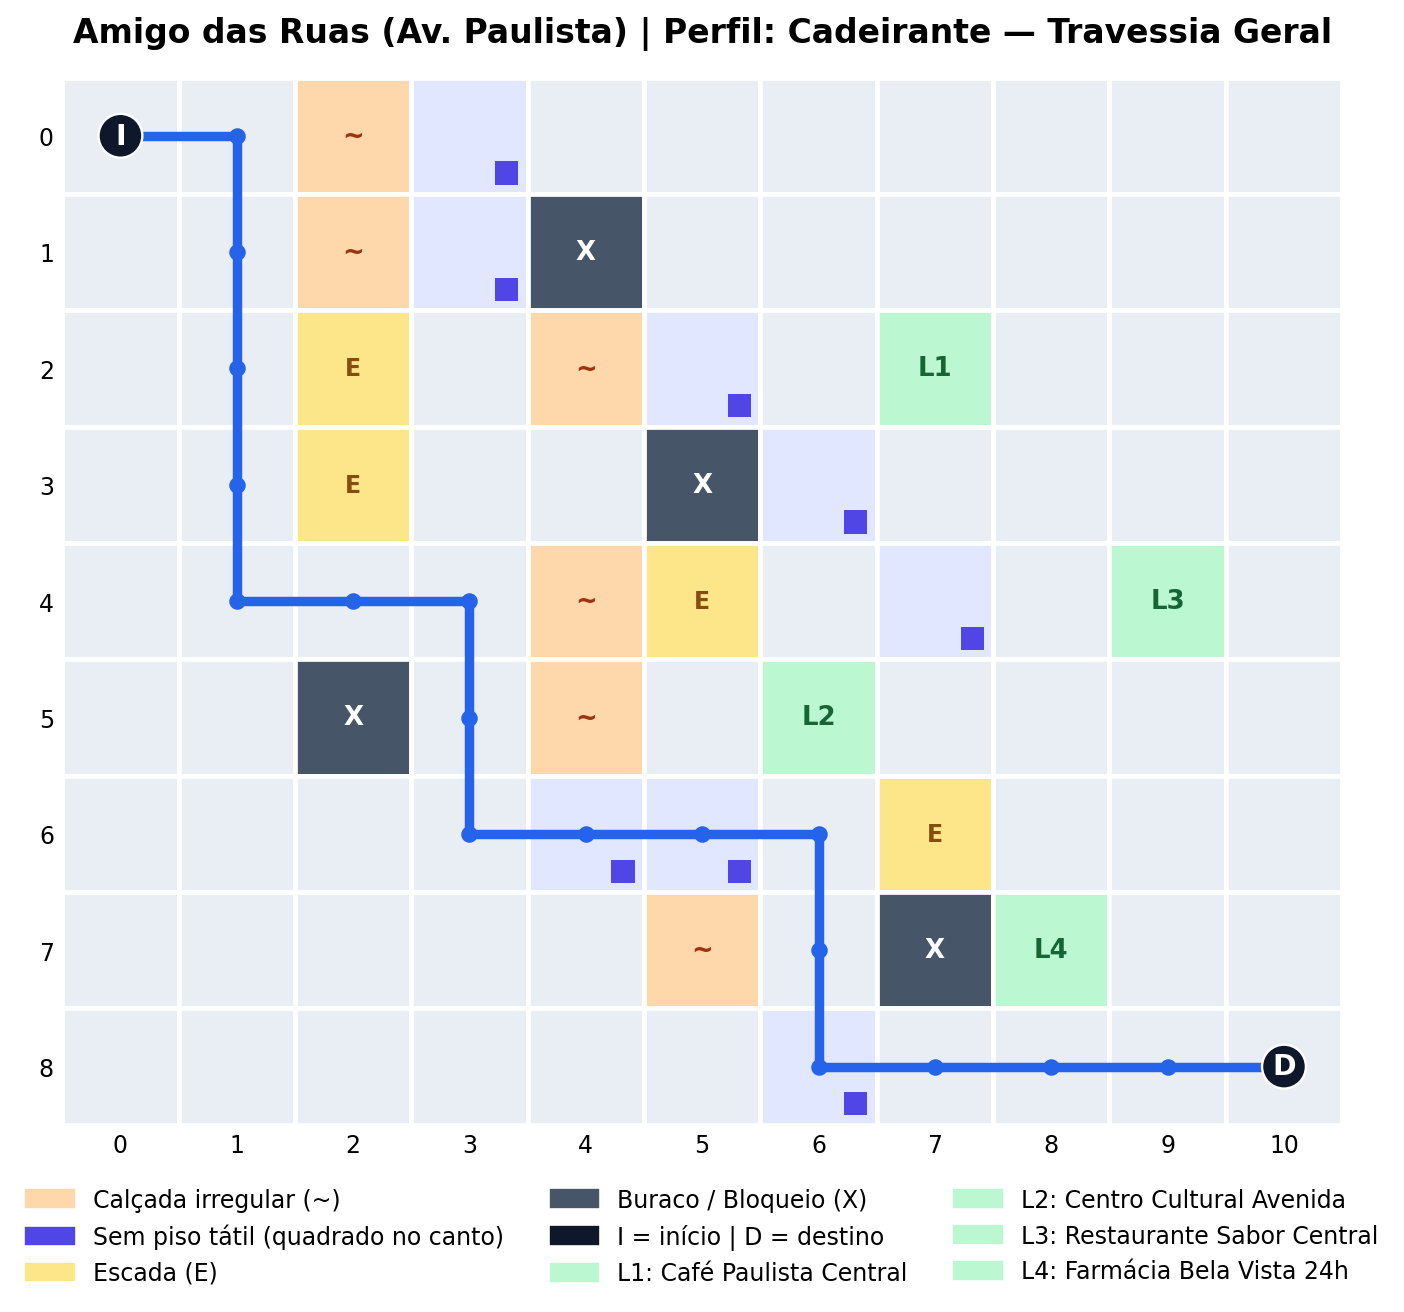


[DEFICIENCIA_VISUAL] 18 trechos | custo acumulado 20.50
  Rota: [(0, 0), (0, 1), (1, 1), (2, 1), (3, 1), (4, 1), (4, 2), (4, 3), (5, 3), (6, 3), (7, 3), (7, 4), (8, 4), (8, 5), (8, 6), (8, 7), (8, 8), (8, 9), (8, 10)]
  Mapa salvo: resultados/rota_paulista_deficiencia_visual.png


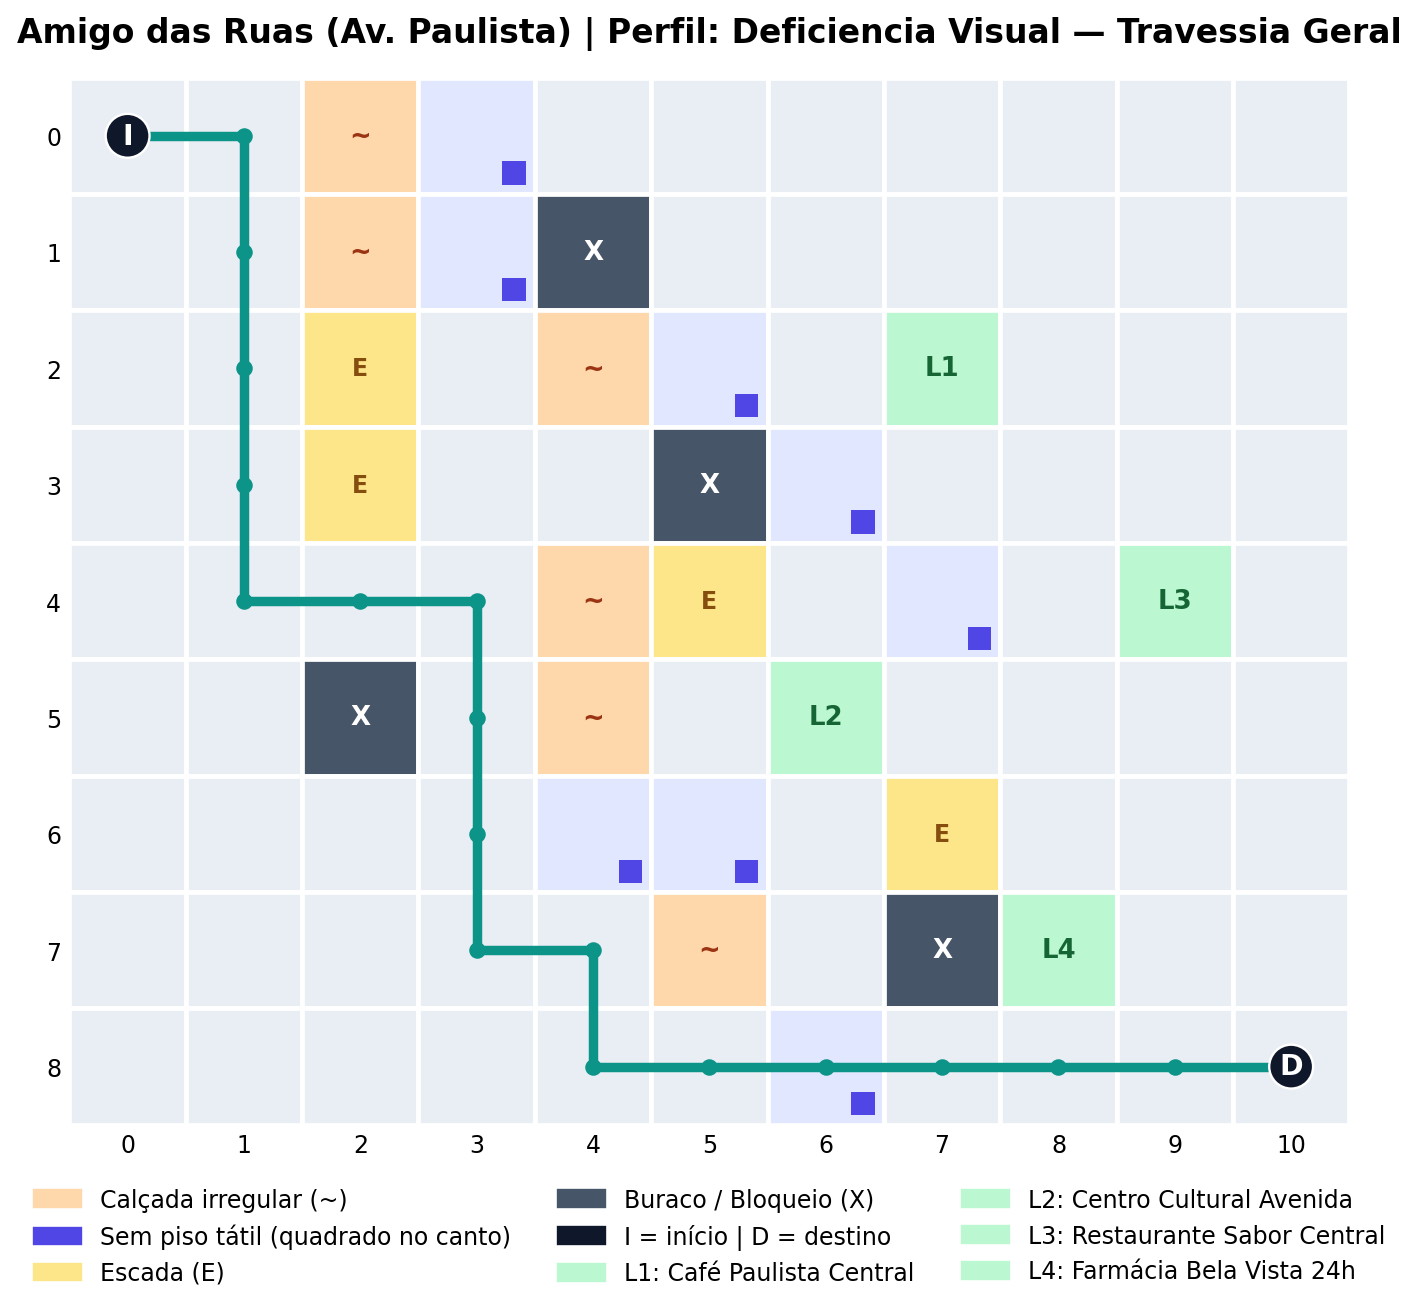


[MOBILIDADE_REDUZIDA] 18 trechos | custo acumulado 18.00
  Rota: [(0, 0), (0, 1), (1, 1), (2, 1), (3, 1), (4, 1), (4, 2), (4, 3), (5, 3), (6, 3), (6, 4), (6, 5), (6, 6), (7, 6), (8, 6), (8, 7), (8, 8), (8, 9), (8, 10)]
  Mapa salvo: resultados/rota_paulista_mobilidade_reduzida.png


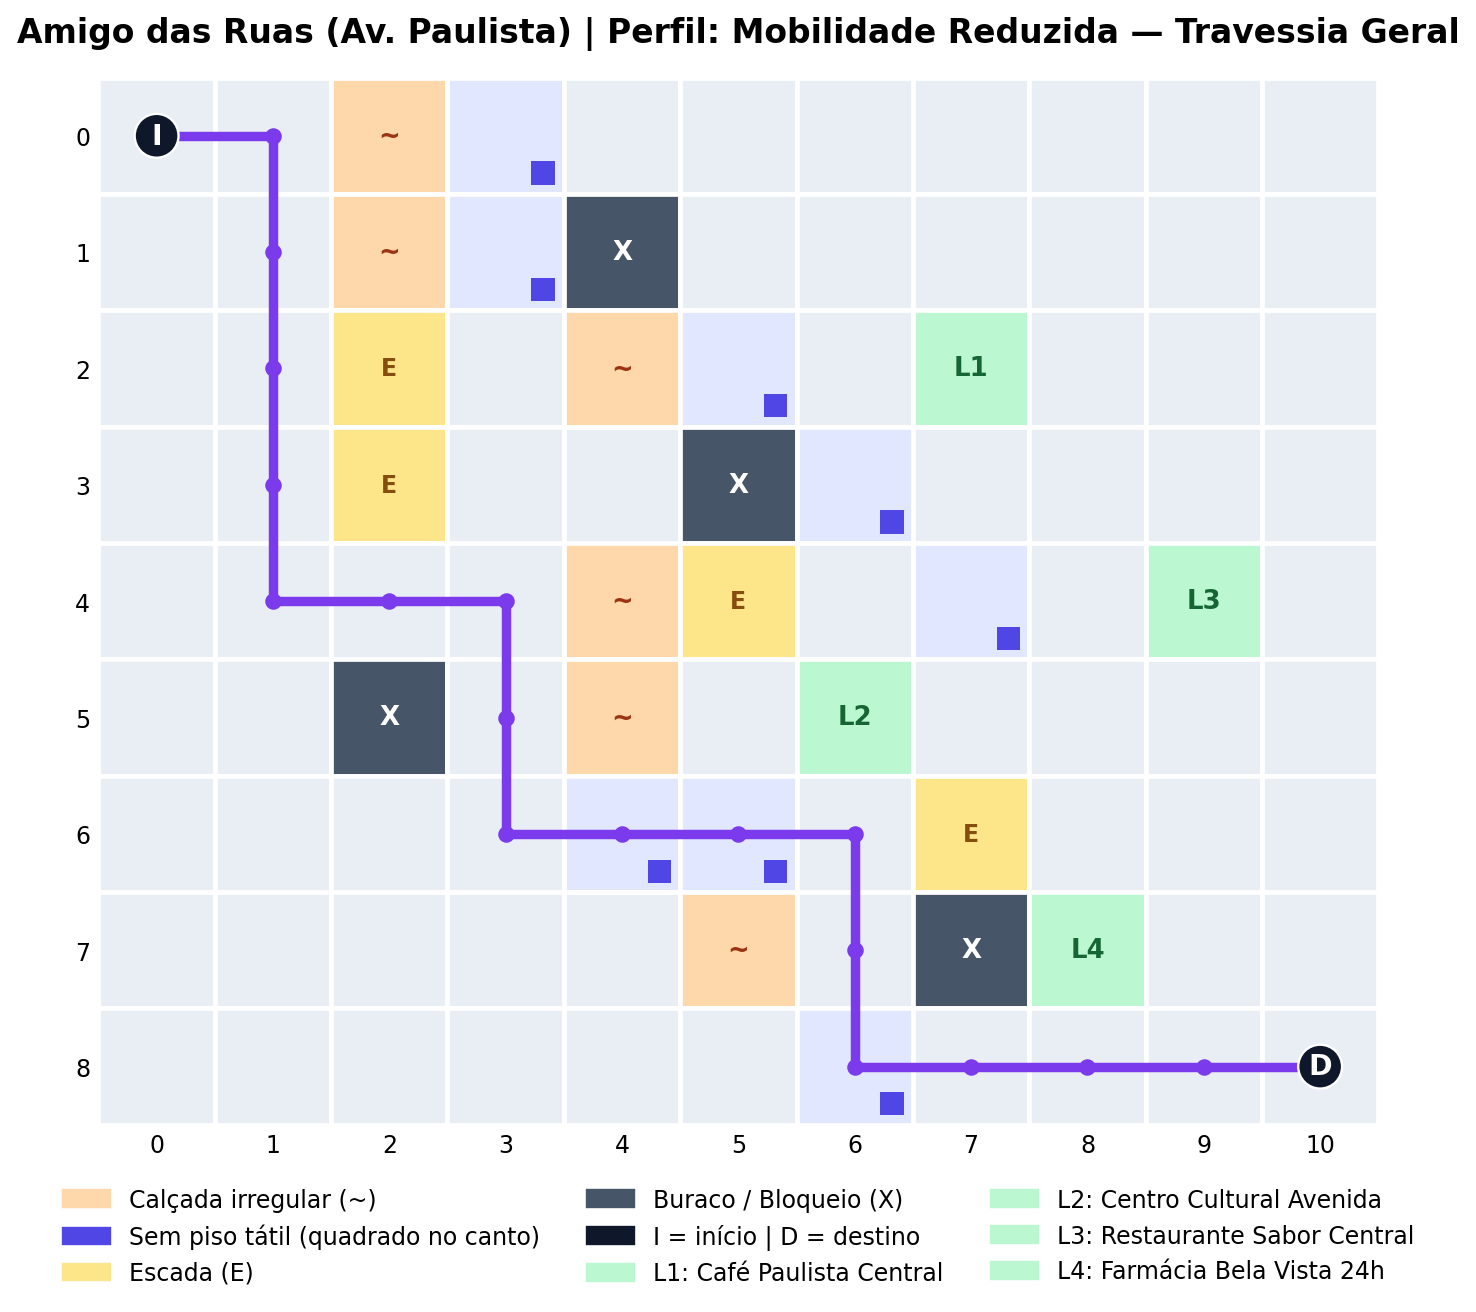


=== 2. PORTAL DE REPUTAÇÃO (ESTILO RECLAME AQUI) + ROTA ATÉ O LOCAL ===

Ranking filtrado para perfil 'cadeirante' (nota >= 5.0):
  1º Centro Cultural Avenida (Cultura) | Nota: 9.5 [Referência em Acessibilidade] | Relatos (Abertos/Resolvidos): 0/12 | Status: Adequação Realizada | Custo Rota: 15.50 | Índice: 7.18
  2º Café Paulista Central (Café) | Nota: 9.2 [Referência em Acessibilidade] | Relatos (Abertos/Resolvidos): 1/6 | Status: Respondido | Custo Rota: 13.50 | Índice: 7.17
  3º Farmácia Bela Vista 24h (Farmácia) | Nota: 8.4 [Bom] | Relatos (Abertos/Resolvidos): 1/4 | Status: Respondido | Custo Rota: 19.50 | Índice: 5.48
  -> Mapa até o 1º colocado salvo em: resultados/melhor_local_cadeirante.png


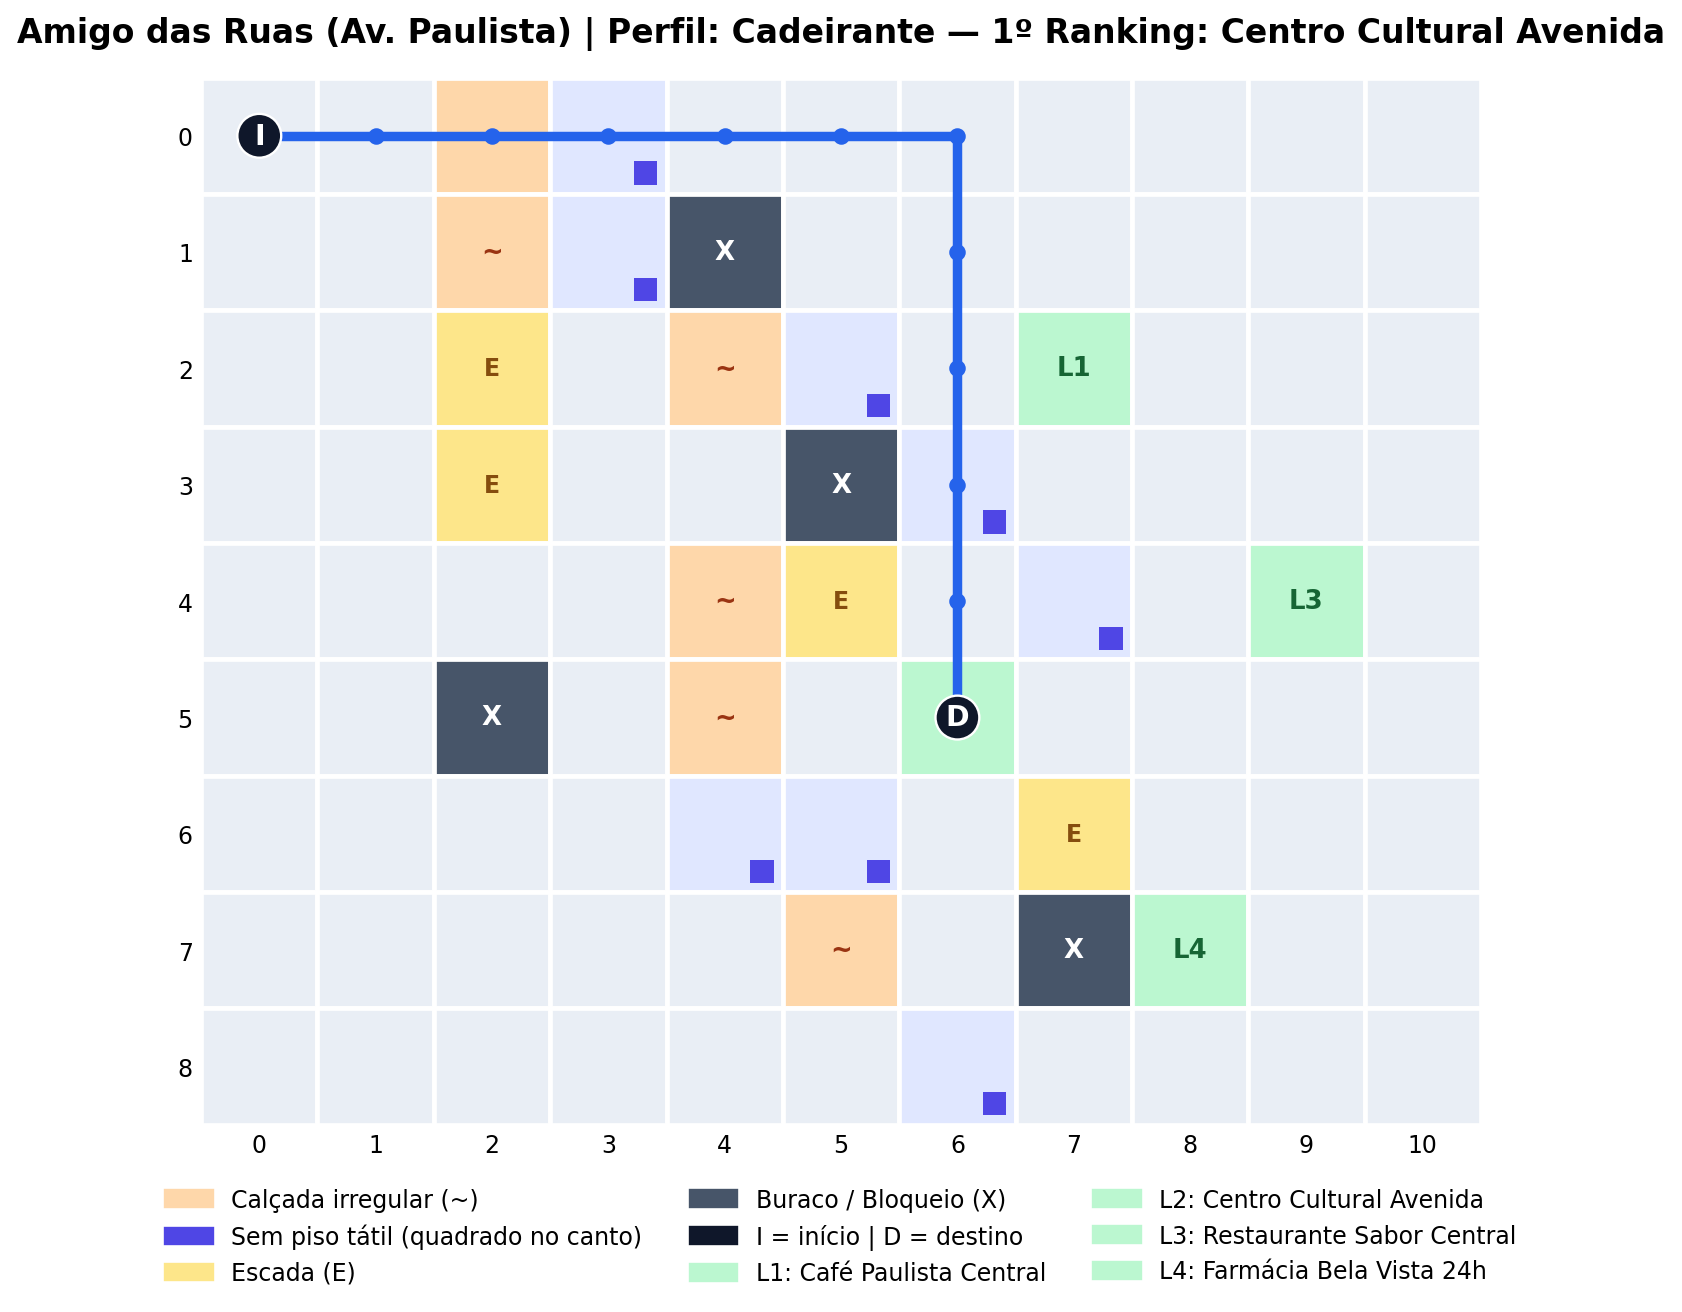


Ranking filtrado para perfil 'deficiencia_visual' (nota >= 5.0):
  1º Centro Cultural Avenida (Cultura) | Nota: 9.4 [Referência em Acessibilidade] | Relatos (Abertos/Resolvidos): 0/12 | Status: Adequação Realizada | Custo Rota: 14.00 | Índice: 7.30
  2º Farmácia Bela Vista 24h (Farmácia) | Nota: 8.1 [Bom] | Relatos (Abertos/Resolvidos): 1/4 | Status: Respondido | Custo Rota: 18.00 | Índice: 5.40
  3º Restaurante Sabor Central (Restaurante) | Nota: 6.8 [Regular] | Relatos (Abertos/Resolvidos): 5/1 | Status: Aberto | Custo Rota: 18.50 | Índice: 4.03
  4º Café Paulista Central (Café) | Nota: 5.6 [Regular] | Relatos (Abertos/Resolvidos): 1/6 | Status: Respondido | Custo Rota: 14.50 | Índice: 3.42
  -> Mapa até o 1º colocado salvo em: resultados/melhor_local_deficiencia_visual.png


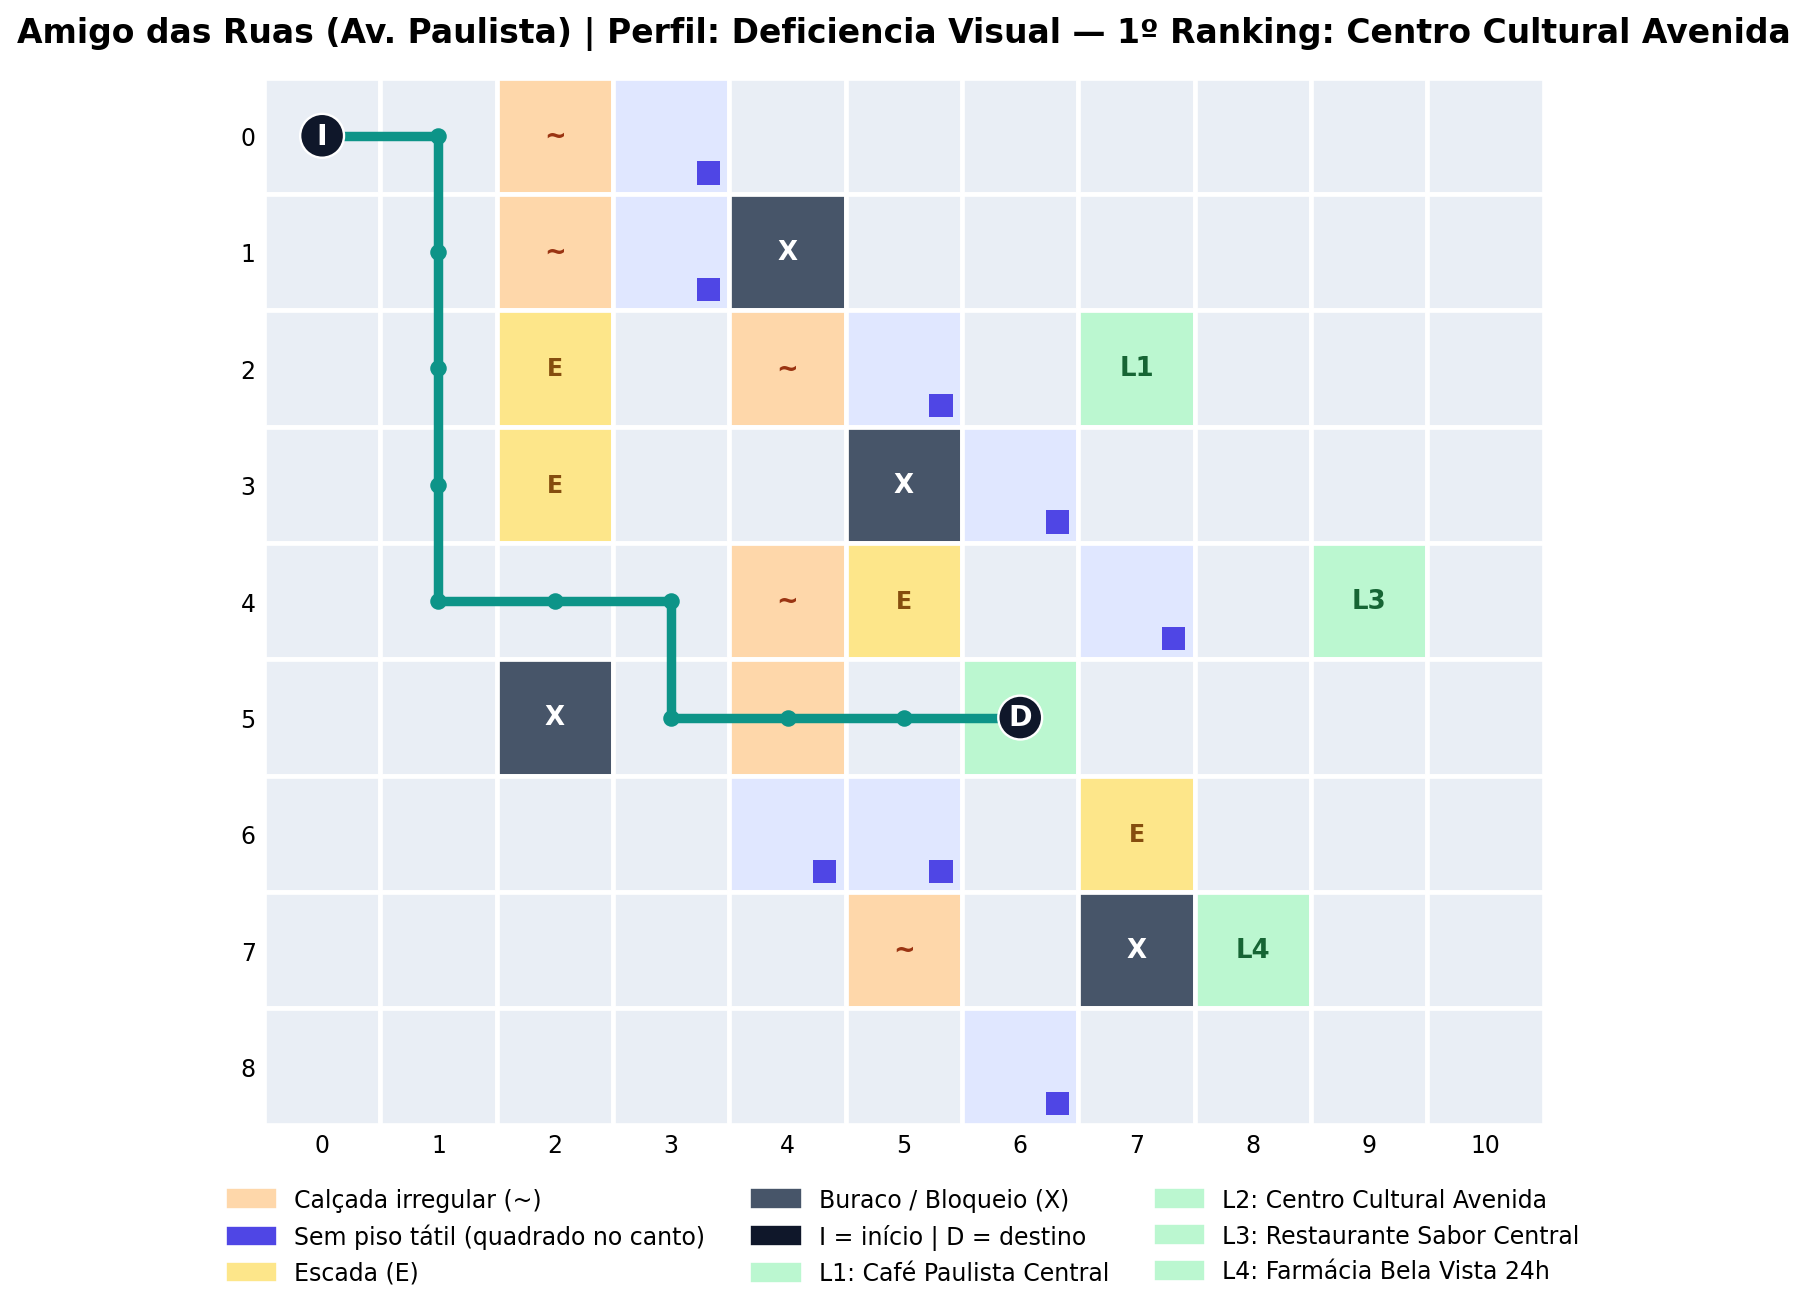


=== 3. RANKINGS DO PORTAL (MAIS ACESSÍVEIS x MAIS RECLAMADOS) ===

Mais Acessíveis — perfil 'cadeirante':
  1º Centro Cultural Avenida | Nota: 9.5 [Referência em Acessibilidade]
  2º Café Paulista Central | Nota: 9.2 [Referência em Acessibilidade]
  3º Farmácia Bela Vista 24h | Nota: 8.4 [Bom]
  4º Restaurante Sabor Central | Nota: 4.2 [Não Recomendado]

Mais Acessíveis — perfil 'deficiencia_visual':
  1º Centro Cultural Avenida | Nota: 9.4 [Referência em Acessibilidade]
  2º Farmácia Bela Vista 24h | Nota: 8.1 [Bom]
  3º Restaurante Sabor Central | Nota: 6.8 [Regular]
  4º Café Paulista Central | Nota: 5.6 [Regular]

Mais Acessíveis — perfil 'mobilidade_reduzida':
  1º Centro Cultural Avenida | Nota: 9.6 [Referência em Acessibilidade]
  2º Café Paulista Central | Nota: 8.8 [Referência em Acessibilidade]
  3º Farmácia Bela Vista 24h | Nota: 8.6 [Referência em Acessibilidade]
  4º Restaurante Sabor Central | Nota: 4.8 [Não Recomendado]

Mais Reclamados (relatos em aberto):
  1º Restaur

In [6]:
def main():
    mapa = criar_mapa()
    executar_testes(mapa)
    pasta = Path("resultados")
    pasta.mkdir(exist_ok=True)

    print("\n=== 1. ROTAS ACESSÍVEIS POR PERFIL (TRAVESSIA DA REGIÃO PAULISTA) ===")
    for perfil in PERFIS:
        dp, anterior = programacao_dinamica(mapa, perfil)
        rota = reconstruir_rota(anterior, dp, DESTINO_PADRAO)
        i, j = DESTINO_PADRAO
        print(f"\n[{perfil.upper()}] {len(rota) - 1} trechos | custo acumulado {dp[i][j]:.2f}")
        print(f"  Rota: {rota}")
        arquivo = pasta / f"rota_paulista_{perfil}.png"
        desenhar_mapa(mapa, rota, DESTINO_PADRAO, perfil, arquivo, titulo_extra="Travessia Geral")
        print(f"  Mapa salvo: {arquivo}")
        exibir(arquivo)

    print("\n=== 2. PORTAL DE REPUTAÇÃO (ESTILO RECLAME AQUI) + ROTA ATÉ O LOCAL ===")
    for perfil in ("cadeirante", "deficiencia_visual"):
        dp, anterior = programacao_dinamica(mapa, perfil)
        ranking = filtrar_e_ranquear_estabelecimentos(dp, anterior, perfil, nota_minima=5.0)
        print(f"\nRanking filtrado para perfil '{perfil}' (nota >= 5.0):")
        for pos, item in enumerate(ranking, start=1):
            est = item["estabelecimento"]
            print(
                f"  {pos}º {est.nome} ({est.categoria}) | Nota: {item['nota_perfil']:.1f} "
                f"[{item['selo']}] | Relatos (Abertos/Resolvidos): {est.relatos_abertos}/{est.relatos_resolvidos} "
                f"| Status: {est.status_relatos()} "
                f"| Custo Rota: {item['custo_rota']:.2f} | Índice: {item['indice_recomendacao']:.2f}"
            )
        melhor = ranking[0]
        est_top = melhor["estabelecimento"]
        arquivo_top = pasta / f"melhor_local_{perfil}.png"
        desenhar_mapa(
            mapa,
            melhor["rota"],
            est_top.posicao,
            perfil,
            arquivo_top,
            titulo_extra=f"1º Ranking: {est_top.nome}",
        )
        print(f"  -> Mapa até o 1º colocado salvo em: {arquivo_top}")
        exibir(arquivo_top)

    print("\n=== 3. RANKINGS DO PORTAL (MAIS ACESSÍVEIS x MAIS RECLAMADOS) ===")
    for perfil in PERFIS:
        print(f"\nMais Acessíveis — perfil '{perfil}':")
        for pos, est in enumerate(ranking_mais_acessiveis(perfil), start=1):
            print(f"  {pos}º {est.nome} | Nota: {est.nota_por_perfil(perfil):.1f} [{est.selo_reputacao(perfil)}]")
    print("\nMais Reclamados (relatos em aberto):")
    for pos, est in enumerate(ranking_mais_reclamados(), start=1):
        print(f"  {pos}º {est.nome} | Abertos: {est.relatos_abertos} | Status: {est.status_relatos()}")

    print("\nConcluído. Todos os obstáculos, notas e estabelecimentos são simulados.")


if __name__ == "__main__":
    main()

## 7. Exemplos de entrada e saída

Dois usos do mesmo motor: uma consulta que encontra locais e uma que **não encontra nenhum** (o sistema informa em vez de inventar uma rota).

In [7]:
def consultar(perfil, categoria=None, nota_minima=0.0):
    """Entrada: perfil, categoria e nota mínima. Saída: locais com selo, status e rota."""
    mapa_ex = criar_mapa()
    dp_ex, ant_ex = programacao_dinamica(mapa_ex, perfil)
    resultado = filtrar_e_ranquear_estabelecimentos(dp_ex, ant_ex, perfil, categoria, nota_minima)
    print(f"ENTRADA: perfil={perfil!r}, categoria={categoria!r}, nota_minima={nota_minima}")
    if not resultado:
        print("SAÍDA: nenhum local atende ao filtro com rota acessível para este perfil.\n")
        return
    for item in resultado:
        est = item["estabelecimento"]
        print(f"SAÍDA: {est.nome} | nota {item['nota_perfil']:.1f} [{item['selo']}] | status {est.status_relatos()}")
        print(f"       {item['trechos']} trechos, custo {item['custo_rota']:.2f}, rota {item['rota']}\n")


consultar("cadeirante", categoria="Café", nota_minima=8.0)             # encontra o Café Paulista Central
consultar("deficiencia_visual", categoria="Café", nota_minima=8.0)     # nota 5,6 para este perfil: nada atende

ENTRADA: perfil='cadeirante', categoria='Café', nota_minima=8.0
SAÍDA: Café Paulista Central | nota 9.2 [Referência em Acessibilidade] | status Respondido
       9 trechos, custo 13.50, rota [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (0, 5), (0, 6), (0, 7), (1, 7), (2, 7)]

ENTRADA: perfil='deficiencia_visual', categoria='Café', nota_minima=8.0
SAÍDA: nenhum local atende ao filtro com rota acessível para este perfil.



## Modelagem e Complexidade

O estado `dp[i][j]` armazena o **menor custo acumulado de acessibilidade** para alcançar a célula `(i, j)` da malha simulada da Avenida Paulista a partir de `(0, 0)`. Para células transitáveis diferentes da origem:

`dp[i][j] = custo(i, j) + min(dp[i-1][j], dp[i][j-1])`

- **Caso base:** `dp[0][0] = 0.0`.
- **Bloqueios (`inf`):** buracos bloqueiam todos os perfis; escadas bloqueiam `cadeirante` e `mobilidade_reduzida`, mas são transponíveis com penalidade para `deficiencia_visual`.
- **Penalidades diferenciadas:** calçadas irregulares e ausência de piso tátil elevam o custo conforme as necessidades de cada perfil, fazendo o algoritmo desviar para trechos mais seguros.
- **Integração com o Portal de Reputação:** após preencher a matriz `dp` em uma única passada, o sistema filtra os estabelecimentos da região por categoria e nota mínima do perfil, combinando a reputação pública com o custo da rota acessível (`nota_perfil - 0,15 × custo_rota`).
- **Complexidade da tabulação:** tempo $O(L \times C)$ e memória $O(L \times C)$ (incluindo a matriz `anterior` para reconstrução do trajeto), evitando a explosão exponencial $O(2^{L+C})$ da recursão pura.

**Limitações acadêmicas:** movimentos para cima e para a esquerda são desconsiderados nesta modelagem em grade. Em geral, obstáculos podem isolar células (o `dp` fica `inf` e não há rota); neste mapa específico, todas as células transitáveis são alcançáveis a partir da origem para os três perfis, o que é verificado em `executar_testes`. Em uma evolução para produção real, a malha seria substituída por um grafo viário multidirecional com dados georreferenciados verificados.

### Regras do portal de reputação (simuladas)

- **Selo:** nota ≥ 8,5 *Referência em Acessibilidade*; ≥ 7,0 *Bom*; ≥ 5,0 *Regular*; abaixo disso *Não Recomendado* (usa a nota do perfil escolhido).
- **Status dos relatos:** sem relatos abertos → *Adequação Realizada*; resolvidos > abertos → *Respondido*; caso contrário → *Aberto*.
- **Índice de recomendação:** `nota_perfil − 0,15 × custo_rota`. O peso 0,15 faz um trecho plano (custo 1) descontar 0,15 ponto de nota, então a reputação decide e a rota desempata. É uma heurística ilustrativa, ajustável pela constante `PESO_CUSTO_ROTA`.
- **Rankings:** *Mais Acessíveis* (maior nota do perfil) e *Mais Reclamados* (mais relatos em aberto).
- **Perfis:** `mobilidade_reduzida` agrupa idosos, pessoas com andador e pessoas com carrinho de bebê, que têm as mesmas restrições de escada e calçada irregular.
- **Cadeirante x mobilidade reduzida:** na travessia completa (0,0) → (8,10) os dois perfis têm a mesma rota e o mesmo custo (18,00), porque escada e buraco bloqueiam ambos e a diferença está só no peso da calçada irregular. A diferença aparece no custo até os locais, por exemplo Café Paulista Central: 13,5 (cadeirante) contra 12,5 (mobilidade reduzida).